# Regional GDP Comparison Across Colombian Departments (2005–2023)

**Student:** Santiago Toro  
**Course:** DAT 301 – Project 2  
**Dataset:** PIB Departamental con Proyección  
**Source:** Gobernación de Caldas, via [Datos Abiertos Colombia](https://www.datos.gov.co)  
**Last Updated:** May 18, 2026  

---

## Background and Problem Definition

Colombia is a highly diverse country composed of 33 departments, each with distinct economic profiles shaped by geography, natural resources, population, and industrial activity. Despite being one of Latin America's largest economies, Colombia faces significant regional economic inequality — some departments like Bogotá D.C. and Antioquia generate a disproportionate share of national GDP, while many others lag far behind.

This project uses the PIB Departamental con Proyección dataset, which provides GDP (Gross Domestic Product) values broken down by department, economic activity, sector, and year from 2005 to 2023, expressed in constant 2015 prices (billions of Colombian pesos).

Research Questions:
1. Which Colombian departments have the highest and lowest total GDP?
2. How has each department's GDP evolved over time (2005–2023)?
3. Which departments experienced the fastest GDP growth?
4. What is the economic sector composition (Primary, Secondary, Tertiary) across departments?
5. What does regional economic inequality look like across Colombia?

---
## 1. Importing Libraries

In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')


plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10

print('Libraries loaded successfully!')

Libraries loaded successfully!


---
## 2. Loading the Dataset

In [52]:
df = pd.read_csv('GDP Data.csv')

print('Shape:', df.shape)
print('\nColumn names:')
print(df.columns.tolist())
print('\nFirst 5 rows:')
df.head()

Shape: (16302, 7)

Column names:
['Año', 'Actividad', 'Sector', 'Tipo de precios', 'Código Departamento (DIVIPOLA)', 'Departamento', 'Valor (miles de millones de pesos)']

First 5 rows:


,Año,Actividad,Sector,Tipo de precios,Código Departamento (DIVIPOLA),Departamento,Valor (miles de millones de pesos)
0,"2,005",Construcción,Secundario,PIB a precios corrientes,97,Vaupés,2.28
1,"2,005",Construcción,Secundario,PIB a precios corrientes,99,Vichada,10.23
2,"2,013",Información y comunicaciones,Terciario,PIB a precios constantes de 2015,15,Boyacá,344.68
3,"2,013",Información y comunicaciones,Terciario,PIB a precios constantes de 2015,17,Caldas,361.68
4,"2,013",Información y comunicaciones,Terciario,PIB a precios constantes de 2015,18,Caquetá,59.84


---
## 3. Data Wrangling, Munging, and Cleaning

After inspecting the dataset, we identified the following issues to fix:
- The **Year** column uses commas as thousand separators (e.g., `"2,005"` instead of `2005`)
- The **Value** column also uses commas as thousand separators (e.g., `"4,856.14"` instead of `4856.14`)
- The dataset contains two price types: **constant prices (2015)** and **current prices** — we will use **constant prices** for fair year-over-year comparisons
- Column names are in Spanish and need renaming for ease of use

In [53]:

df.columns = ['Year', 'Activity', 'Sector', 'PriceType', 'DeptCode', 'Department', 'Value']


df['Year'] = df['Year'].astype(str).str.replace(',', '').astype(int)


df['Value'] = df['Value'].astype(str).str.replace(',', '').astype(float)

print('Data types after cleaning:')
print(df.dtypes)
print('\nYear range:', df['Year'].min(), '–', df['Year'].max())
print('Number of departments:', df['Department'].nunique())
print('Price types:', df['PriceType'].unique())

Data types after cleaning:
Year            int64
Activity          str
Sector            str
PriceType         str
DeptCode        int64
Department        str
Value         float64
dtype: object

Year range: 2005 – 2023
Number of departments: 33
Price types: <StringArray>
['PIB a precios corrientes', 'PIB a precios constantes de 2015']
Length: 2, dtype: str


In [54]:
# Check for missing values
print('Missing values per column:')
print(df.isnull().sum())
print('\nTotal rows:', len(df))

Missing values per column:
Year          0
Activity      0
Sector        0
PriceType     0
DeptCode      0
Department    0
Value         0
dtype: int64

Total rows: 16302


In [55]:
# Filter for constant 2015 prices only
df_const = df[df['PriceType'] == 'PIB a precios constantes de 2015'].copy()

print(f'Rows with constant prices: {len(df_const)}')
print(f'Rows with current prices (excluded): {len(df) - len(df_const)}')


print('\nDepartments in dataset:')
print(sorted(df_const['Department'].unique()))

Rows with constant prices: 8151
Rows with current prices (excluded): 8151

Departments in dataset:
['Amazonas', 'Antioquia', 'Arauca', 'Atlántico', 'Bogotá D.C.', 'Bolívar', 'Boyacá', 'Caldas', 'Caquetá', 'Casanare', 'Cauca', 'Cesar', 'Chocó', 'Cundinamarca', 'Córdoba', 'Guainía', 'Guaviare', 'Huila', 'La Guajira', 'Magdalena', 'Meta', 'Nariño', 'Norte de Santander', 'Putumayo', 'Quindío', 'Risaralda', 'San Andrés, Providencia y Santa Catalina (Archipiélago)', 'Santander', 'Sucre', 'Tolima', 'Valle del Cauca', 'Vaupés', 'Vichada']


In [56]:
# Aggregate total GDP per department per year
gdp_by_dept_year = df_const.groupby(['Year', 'Department'])['Value'].sum().reset_index()
gdp_by_dept_year.columns = ['Year', 'Department', 'TotalGDP']

print('Aggregated data shape:', gdp_by_dept_year.shape)
gdp_by_dept_year.head(10)

Aggregated data shape: (627, 3)


,Year,Department,TotalGDP
0,2005,Amazonas,430.35
1,2005,Antioquia,75948.47
2,2005,Arauca,4992.27
3,2005,Atlántico,22703.97
4,2005,Bogotá D.C.,135230.91
5,2005,Bolívar,18759.66
6,2005,Boyacá,13280.41
7,2005,Caldas,9636.17
8,2005,Caquetá,2128.41
9,2005,Casanare,9575.06


---
## 4. Exploratory Data Analysis

### 4.1 Summary Statistics

In [57]:
print('=== Summary Statistics: Total GDP (billions COP, constant 2015 prices) ===')
print(gdp_by_dept_year['TotalGDP'].describe().round(2))

=== Summary Statistics: Total GDP (billions COP, constant 2015 prices) ===
count       627.00
mean      22888.00
std       39031.39
min         130.81
25%        3548.19
50%       10984.22
75%       19861.10
max      261669.80
Name: TotalGDP, dtype: float64


In [58]:
# Average GDP per department across all years
avg_gdp = gdp_by_dept_year.groupby('Department')['TotalGDP'].mean().sort_values(ascending=False)

print('=== Average GDP by Department (2005–2023) ===')
print(avg_gdp.round(2).to_string())

=== Average GDP by Department (2005–2023) ===
Department
Bogotá D.C.                                                195908.33
Antioquia                                                  109736.67
Valle del Cauca                                             74802.76
Santander                                                   48583.14
Cundinamarca                                                45288.96
Atlántico                                                   33204.33
Bolívar                                                     27178.21
Meta                                                        24488.88
Boyacá                                                      20063.89
Tolima                                                      16428.18
Cesar                                                       13568.14
Córdoba                                                     13087.40
Cauca                                                       13077.22
Huila                                         

### 4.2 GDP Rankings: Richest and Poorest Departments

We compare total GDP for the most recent available year to see the current economic landscape.

In [59]:
# Most recent year available
latest_year = gdp_by_dept_year['Year'].max()
print(f'Most recent year in dataset: {latest_year}')

latest_gdp = gdp_by_dept_year[gdp_by_dept_year['Year'] == latest_year].sort_values('TotalGDP', ascending=False)
latest_gdp = latest_gdp.reset_index(drop=True)
latest_gdp.index += 1  # Start ranking from 1

print(f'\n=== GDP Rankings for {latest_year} (billions COP, constant 2015 prices) ===')
print(latest_gdp[['Department', 'TotalGDP']].to_string())

Most recent year in dataset: 2023

=== GDP Rankings for 2023 (billions COP, constant 2015 prices) ===
                                                 Department   TotalGDP
1                                               Bogotá D.C.  261669.80
2                                                 Antioquia  146126.79
3                                           Valle del Cauca   97502.75
4                                                 Santander   61664.41
5                                              Cundinamarca   59788.20
6                                                 Atlántico   44690.11
7                                                   Bolívar   35868.10
8                                                      Meta   30520.02
9                                                    Boyacá   24694.04
10                                                   Tolima   19719.02
11                                                    Cauca   16965.35
12                                            

### 4.3 GDP Growth Rate Analysis

We calculate the total GDP growth rate for each department from 2005 to the most recent year.

In [60]:

gdp_2005 = gdp_by_dept_year[gdp_by_dept_year['Year'] == 2005].set_index('Department')['TotalGDP']
gdp_latest = gdp_by_dept_year[gdp_by_dept_year['Year'] == latest_year].set_index('Department')['TotalGDP']

# Calculate overall growth rate (%)
growth = ((gdp_latest - gdp_2005) / gdp_2005 * 100).dropna().sort_values(ascending=False)
growth = growth.round(1)

print(f'=== Total GDP Growth Rate by Department (2005 → {latest_year}) ===')
for dept, rate in growth.items():
    print(f'{dept:<55} {rate:>8.1f}%')

=== Total GDP Growth Rate by Department (2005 → 2023) ===
Meta                                                       193.1%
Putumayo                                                   119.9%
Vaupés                                                     108.1%
Sucre                                                      102.9%
Cauca                                                       97.8%
Cundinamarca                                                97.7%
Atlántico                                                   96.8%
Bogotá D.C.                                                 93.5%
Antioquia                                                   92.4%
Norte de Santander                                          91.3%
Bolívar                                                     91.2%
Valle del Cauca                                             87.2%
Boyacá                                                      85.9%
Quindío                                                     85.2%
San Andrés, Provid

### 4.4 Sector Composition Analysis

Each activity belongs to a sector: Primary (agriculture, mining), Secondary (manufacturing, construction), or Tertiary (services). We compare how the economic structure differs across departments.

In [61]:
# Sector breakdown per department 
sector_df = df_const[df_const['Year'] == latest_year].groupby(['Department', 'Sector'])['Value'].sum().reset_index()
sector_pivot = sector_df.pivot(index='Department', columns='Sector', values='Value').fillna(0)


sector_pivot['Total'] = sector_pivot.sum(axis=1)
sector_pct = sector_pivot.drop(columns='Total').div(sector_pivot['Total'], axis=0) * 100
sector_pct = sector_pct.round(1)

print(f'=== Sector Composition (%) by Department — {latest_year} ===')
print(sector_pct.sort_values('Terciario', ascending=False).to_string())

=== Sector Composition (%) by Department — 2023 ===
Sector                                                   Primario  Secundario  Terciario
Department                                                                              
San Andrés, Providencia y Santa Catalina (Archipiélago)       1.3         3.3       95.4
Bogotá D.C.                                                   0.1        11.1       88.7
Vaupés                                                        7.1         7.9       85.0
Atlántico                                                     1.3        19.9       78.8
Amazonas                                                     17.2         5.3       77.4
Nariño                                                       14.5         8.3       77.2
Magdalena                                                    13.8         9.2       77.0
Caquetá                                                      15.2         8.4       76.4
Valle del Cauca                                           

---
## 5. Data Visualization

### 5.1 Top 10 and Bottom 10 Departments by GDP

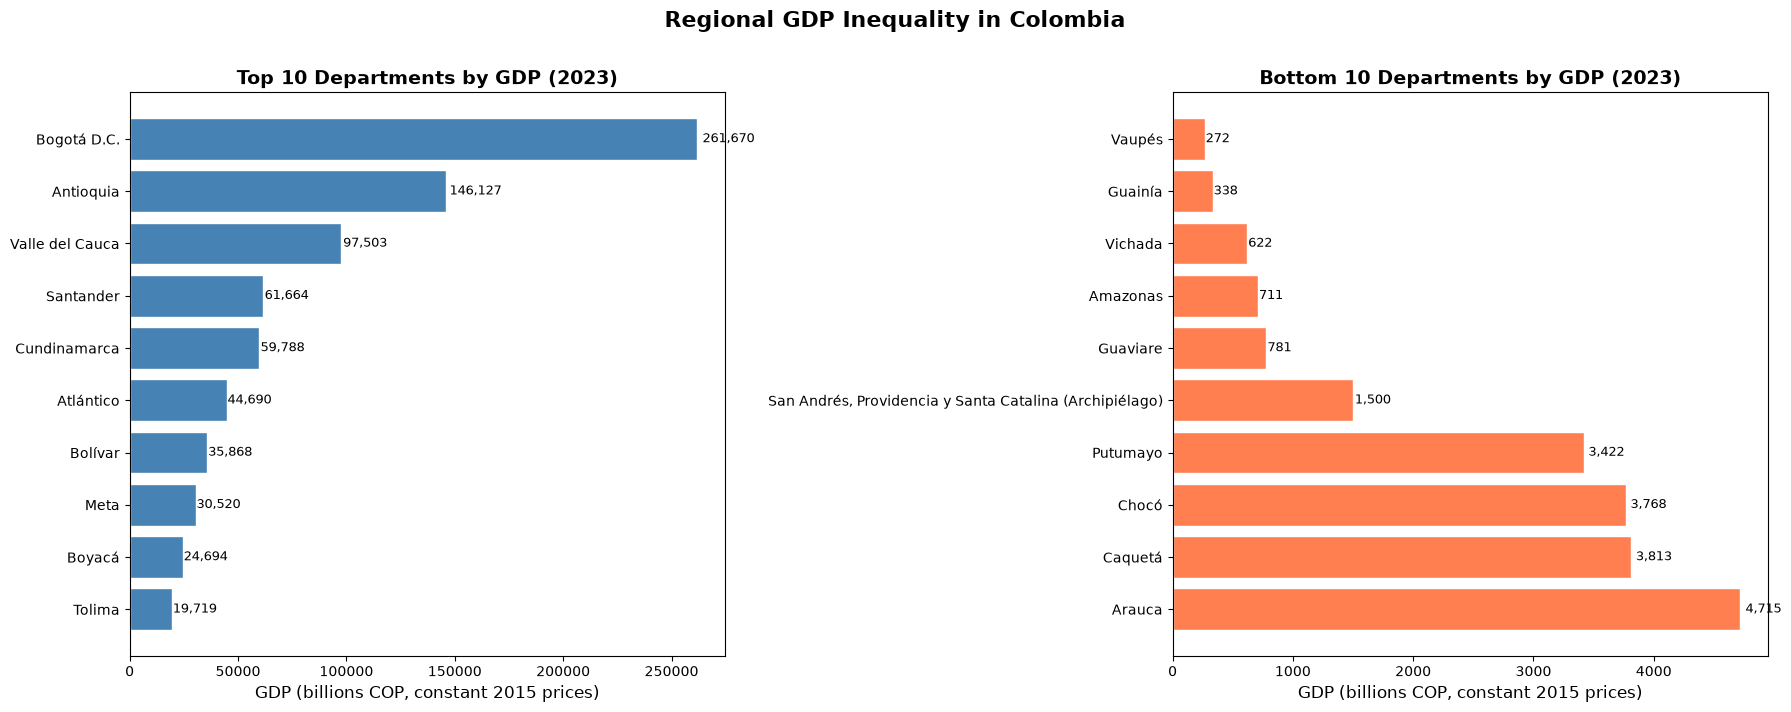

Figure saved as plot1_gdp_ranking.png


In [62]:
latest_sorted = latest_gdp.sort_values('TotalGDP', ascending=False).reset_index(drop=True)
top10 = latest_sorted.head(10)
bottom10 = latest_sorted.tail(10).sort_values('TotalGDP', ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Top 10
bars1 = axes[0].barh(top10['Department'], top10['TotalGDP'], color='steelblue', edgecolor='white')
axes[0].set_title(f'Top 10 Departments by GDP ({latest_year})', fontweight='bold')
axes[0].set_xlabel('GDP (billions COP, constant 2015 prices)')
axes[0].invert_yaxis()
for bar, val in zip(bars1, top10['TotalGDP']):
    axes[0].text(bar.get_width() * 1.01, bar.get_y() + bar.get_height()/2,
                 f'{val:,.0f}', va='center', fontsize=9)

# Bottom 10
bars2 = axes[1].barh(bottom10['Department'], bottom10['TotalGDP'], color='coral', edgecolor='white')
axes[1].set_title(f'Bottom 10 Departments by GDP ({latest_year})', fontweight='bold')
axes[1].set_xlabel('GDP (billions COP, constant 2015 prices)')
axes[1].invert_yaxis()
for bar, val in zip(bars2, bottom10['TotalGDP']):
    axes[1].text(bar.get_width() * 1.01, bar.get_y() + bar.get_height()/2,
                 f'{val:,.0f}', va='center', fontsize=9)

plt.suptitle('Regional GDP Inequality in Colombia', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('plot1_gdp_ranking.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as plot1_gdp_ranking.png')

**Observation:** There is an extreme concentration of economic output in a few departments. Bogotá D.C. and Antioquia alone account for a massive share of national GDP, while territories like Vaupés, Guainía, and Vichada produce very little. This reflects both population differences and the structural concentration of industry and services in urban hubs.

### 5.2 GDP Over Time: Top 6 Departments

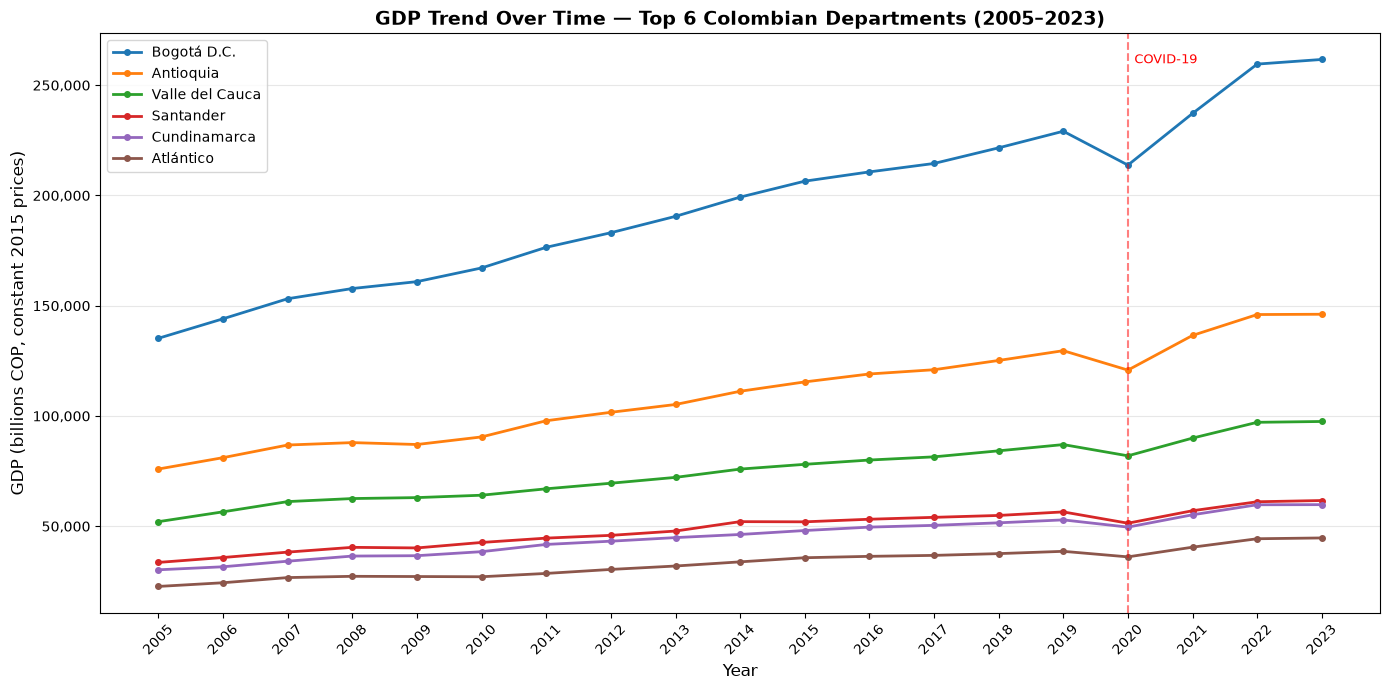

Figure saved as plot2_gdp_trend.png


In [63]:
# Select top 6 departments by latest GDP for the line chart
top6_depts = latest_sorted.head(6)['Department'].tolist()

fig, ax = plt.subplots(figsize=(14, 7))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

for i, dept in enumerate(top6_depts):
    dept_data = gdp_by_dept_year[gdp_by_dept_year['Department'] == dept].sort_values('Year')
    ax.plot(dept_data['Year'], dept_data['TotalGDP'], marker='o', markersize=4,
            label=dept, color=colors[i], linewidth=2)

ax.set_title('GDP Trend Over Time — Top 6 Colombian Departments (2005–2023)', fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('GDP (billions COP, constant 2015 prices)')
ax.legend(loc='upper left', fontsize=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.grid(axis='y', alpha=0.3)
ax.set_xticks(gdp_by_dept_year['Year'].unique())
ax.tick_params(axis='x', rotation=45)

# Highlight COVID-19 year
ax.axvline(x=2020, color='red', linestyle='--', alpha=0.5, label='COVID-19 (2020)')
ax.text(2020.1, ax.get_ylim()[1]*0.95, 'COVID-19', color='red', fontsize=9)

plt.tight_layout()
plt.savefig('plot2_gdp_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as plot2_gdp_trend.png')

**Observation:** All top departments show a clear upward GDP trend from 2005 to 2023, with a visible dip around 2020 caused by the COVID-19 pandemic. Bogotá D.C. leads by a wide margin, followed by Antioquia and Valle del Cauca. The gap between these top departments and others appears to be widening over time.

### 5.3 GDP Growth Rate by Department (2005 → latest year)

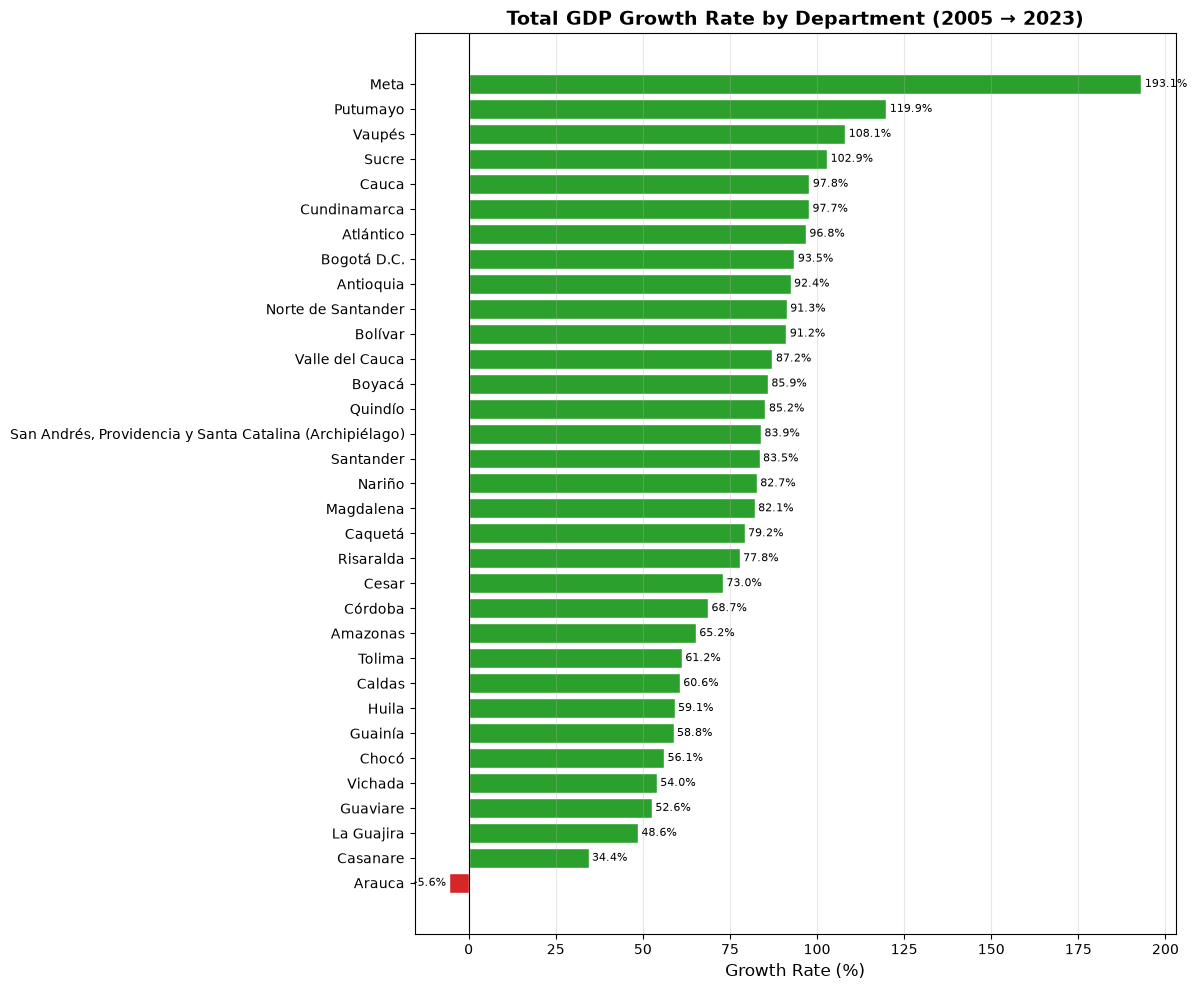

Figure saved as plot3_growth_rate.png


In [64]:
growth_sorted = growth.sort_values(ascending=True)
colors_growth = ['#2ca02c' if x >= 0 else '#d62728' for x in growth_sorted]

fig, ax = plt.subplots(figsize=(12, 10))
bars = ax.barh(growth_sorted.index, growth_sorted.values, color=colors_growth, edgecolor='white')

ax.set_title(f'Total GDP Growth Rate by Department (2005 → {latest_year})', fontweight='bold')
ax.set_xlabel('Growth Rate (%)')
ax.axvline(x=0, color='black', linewidth=0.8)

for bar, val in zip(bars, growth_sorted.values):
    x_pos = bar.get_width() + 1 if val >= 0 else bar.get_width() - 1
    ha = 'left' if val >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}%', va='center', ha=ha, fontsize=8)

ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('plot3_growth_rate.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as plot3_growth_rate.png')

**Observation:** Most departments have experienced positive GDP growth between 2005 and the most recent year. Departments that grew the fastest tend to be those that industrialized more, attracted investment, or benefited from commodity booms. Any department with negative growth may reflect structural decline or a shift in reporting.

### 5.4 Heatmap: GDP by Department and Year

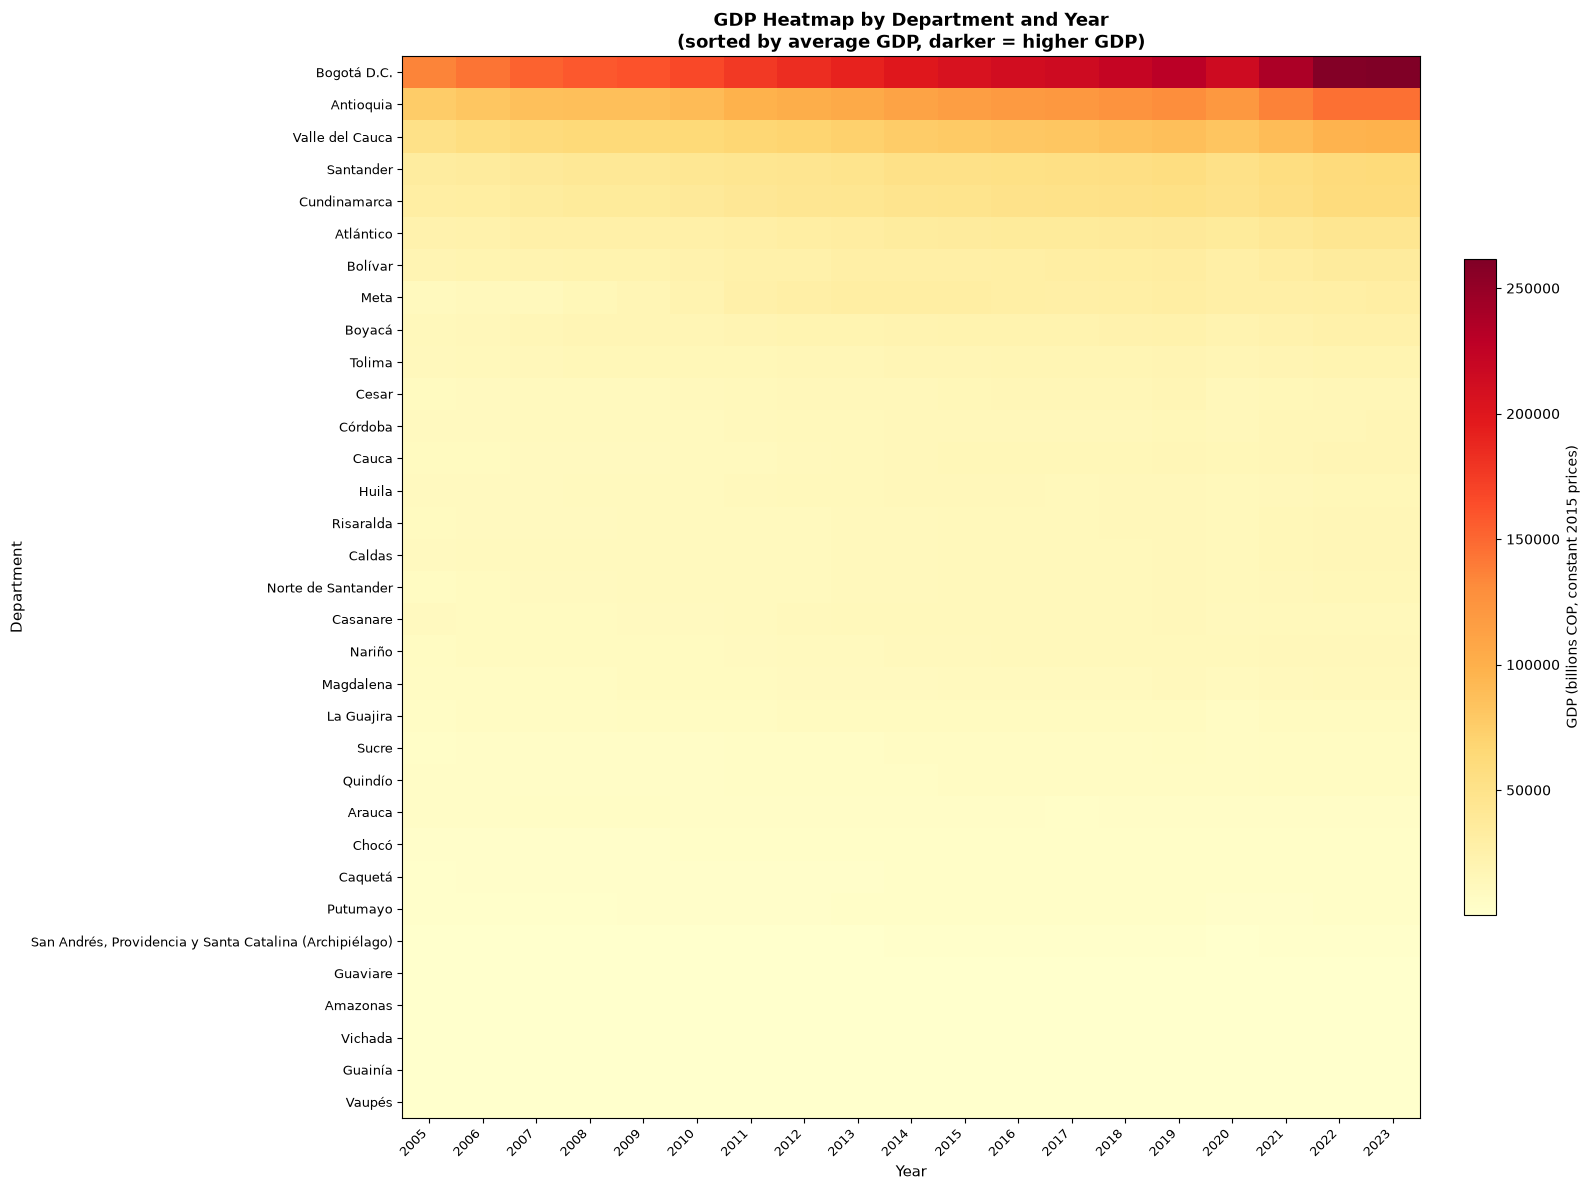

Figure saved as plot4_heatmap.png


In [65]:
# Pivot for heatmap
heatmap_data = gdp_by_dept_year.pivot(index='Department', columns='Year', values='TotalGDP')

# Sort departments by average GDP
heatmap_data = heatmap_data.loc[heatmap_data.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(16, 12))
im = ax.imshow(heatmap_data.values, aspect='auto', cmap='YlOrRd')

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=45, ha='right', fontsize=9)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index, fontsize=9)

cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.04)
cbar.set_label('GDP (billions COP, constant 2015 prices)', fontsize=10)

ax.set_title('GDP Heatmap by Department and Year\n(sorted by average GDP, darker = higher GDP)',
             fontweight='bold', fontsize=13)
ax.set_xlabel('Year', fontsize=11)
ax.set_ylabel('Department', fontsize=11)

plt.tight_layout()
plt.savefig('plot4_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as plot4_heatmap.png')

**Observation:** The heatmap clearly shows the extreme concentration of GDP in Bogotá D.C. and Antioquia (darkest colors at the top). The majority of departments remain in very low GDP ranges (light colors) throughout the entire period. The gradual darkening from left to right also confirms general GDP growth over the years for most departments.

### 5.5 Sector Composition: Stacked Bar Chart (Top 10 Departments)

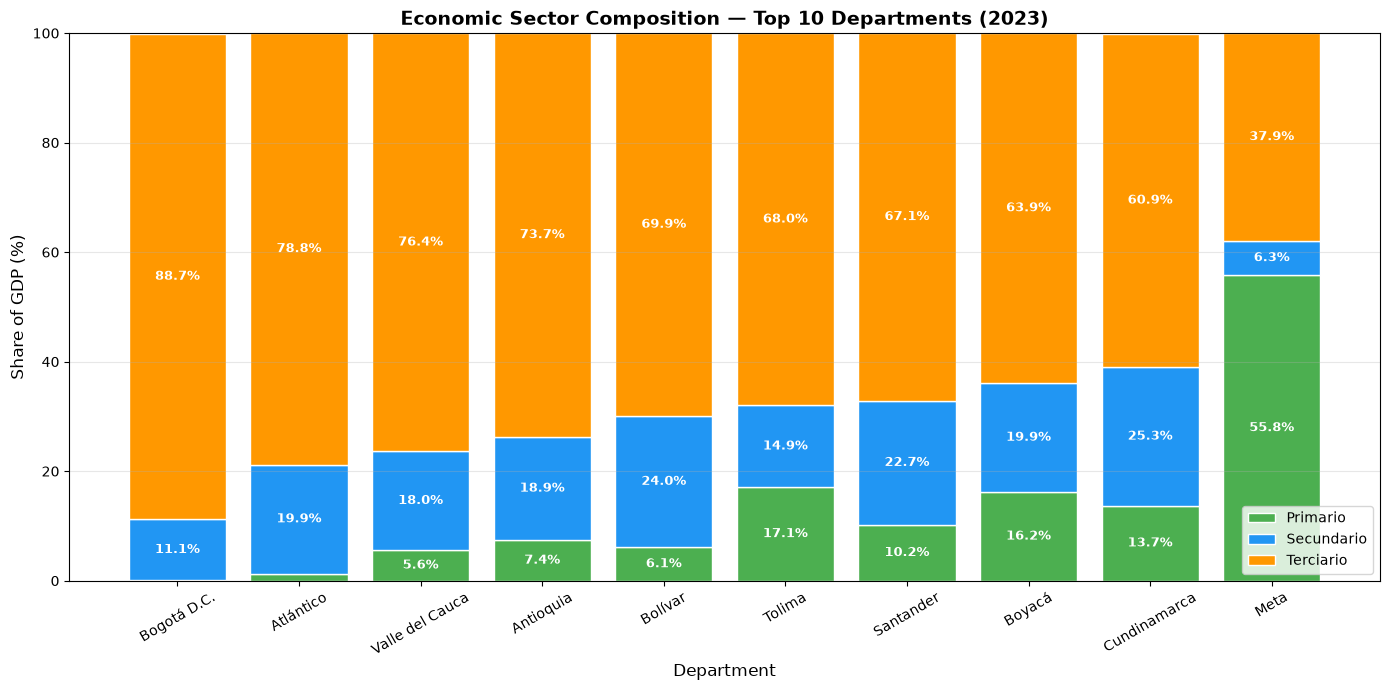

Figure saved as plot5_sector_composition.png


In [66]:
# Get top 10 departments
top10_depts = latest_sorted.head(10)['Department'].tolist()
sector_top10 = sector_pct.loc[sector_pct.index.isin(top10_depts)]


sector_top10 = sector_top10.sort_values('Terciario', ascending=False)

# Available sectors
available_sectors = [s for s in ['Primario', 'Secundario', 'Terciario'] if s in sector_top10.columns]
sector_colors = {'Primario': '#4CAF50', 'Secundario': '#2196F3', 'Terciario': '#FF9800'}

fig, ax = plt.subplots(figsize=(14, 7))

bottom = np.zeros(len(sector_top10))
for sector in available_sectors:
    values = sector_top10[sector].values
    bars = ax.bar(sector_top10.index, values, bottom=bottom,
                  label=sector, color=sector_colors[sector], edgecolor='white')
    
    for bar, val, bot in zip(bars, values, bottom):
        if val > 5:
            ax.text(bar.get_x() + bar.get_width()/2, bot + val/2,
                    f'{val:.1f}%', ha='center', va='center', fontsize=9, color='white', fontweight='bold')
    bottom += values

ax.set_title(f'Economic Sector Composition — Top 10 Departments ({latest_year})', fontweight='bold')
ax.set_ylabel('Share of GDP (%)')
ax.set_xlabel('Department')
ax.set_ylim(0, 100)
ax.tick_params(axis='x', rotation=30)
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('plot5_sector_composition.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved as plot5_sector_composition.png')

**Observation:** Among the top-GDP departments, the **Tertiary sector** (services, commerce, finance) dominates — especially in Bogotá D.C., which is Colombia's financial and services hub. Departments more reliant on natural resources show a higher **Primary sector** share. This sector composition analysis reveals not just how much each department produces, but *how* they produce it.

---
## 6. Conclusions

This analysis of Colombian departmental GDP from 2005 to 2023 reveals several key findings:

1. **Extreme regional inequality exists in Colombia.** Bogotá D.C. and Antioquia dominate the national GDP, while small territories like Vaupés, Guainía, and Vichada contribute minimally. This reflects deep structural disparities in population, infrastructure, and economic opportunity.

2. **GDP has grown across most departments over the period**, indicating broad economic development. However, the gap between the richest and poorest departments has not narrowed significantly.

3. **The COVID-19 pandemic caused a visible dip in 2020** across all departments, particularly in service-heavy ones. Recovery to pre-pandemic levels occurred within 1–2 years for most departments.

4. **Some mid-sized departments showed strong growth rates**, suggesting that economic dynamism is not exclusive to the largest departments — development policies and regional investment can make a difference.

5. **Tertiary (service) sector dominance** characterizes the most economically developed departments, while primary sector dependence is more common in less developed or rural departments, making them more vulnerable to commodity price fluctuations.

**Data Source:**  
Gobernación de Caldas. *PIB Departamental con Proyección.* Retrieved from [Datos Abiertos Colombia](https://www.datos.gov.co). Last updated: May 18, 2026.